In [1]:
import pickle
import os

import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

#import models.vgg as models
#import models.densenet as models
import models.chexpert.classifier as classifier
from easydict import EasyDict as edict

torch.set_printoptions(sci_mode=False)

import lrp
from models.lrp_converter import convert

from PIL import Image

from utils import get_device, heatmap, project

/home/jack/anaconda3/envs/playing_cards/lib/python3.10/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from dataset.dataset import load_data
from dataset.utils import *

def get_dataset(return_orig=False, return_path=False, shuffle=True):
	n_concepts = 5
	#val_loader = load_data("../dataset/chexpert/splits/CBM_5_obs/test.pkl", 32, dataset_root="../dataset/chexpert/", return_orig=return_orig, return_path=return_path, shuffle=shuffle, dataset_name="chexpert", x_resize=512, y_resize=512)
	#concept_index_to_string = IndexToString("../dataset/chexpert/splits/CBM_5_obs/concepts.txt")
	
	val_loader = load_data("../dataset/ChestX-ray14/splits/CBM/test.pkl", 32, dataset_root="../dataset/ChestX-ray14/", return_orig=return_orig, return_path=return_path, shuffle=shuffle, dataset_name="xray14", x_resize=512, y_resize=512, keep_concepts=[10, 4, 1, 0, 7], bb_only=True)
	concept_index_to_string = IndexToString("../dataset/chexpert/splits/CBM_5_obs/concepts.txt")  # use the same labels as chexpert

	return n_concepts, val_loader, concept_index_to_string

In [3]:
device = get_device(cpu=True)

N_CONCEPT, test_loader, concept_index_to_string = get_dataset(return_orig=True, return_path=False, shuffle=True)

#XtoC = models.vgg19_bn(pretrained=True, num_classes=N_CONCEPT)

#backbone = models.densenet121(pretrained=False, num_classes=1000)
#XtoC = models.XtoC(backbone, global_pool_type="AVG_MAX", num_classes=[1,1,1,1,1], fc_bn=True, fc_drop=0, lse_gamma=0.5)

cfg = edict({
	"backbone": "densenet121",
	"norm_type": "BatchNorm",
	"pretrained": True,
	"num_classes": [1,1,1,1,1],
})

XtoC = classifier.Classifier(cfg)

#XtoC.load_state_dict(torch.load("./../saves/chexpert_XtoC_converted.pth"))
#XtoC.load_state_dict(torch.load("./../saves/chexpert_x_to_c.pth", map_location=torch.device('cpu')))
#XtoC.load_state_dict(torch.load("./../saves/densenet121_chexpert.pth", map_location=torch.device('cpu')), strict=False)
#XtoC.load_state_dict(torch.load("./../saves/chexpert_5_obs/best1.ckpt", map_location=torch.device('cpu'))['state_dict'], strict=False)
XtoC.load_state_dict(torch.load("./../saves/chexpert/chexpert_0.ckpt", map_location=torch.device('cpu'))['state_dict'], strict=True)
XtoC.to(device)
XtoC.eval()

print("model loaded")

/home/jack/anaconda3/envs/playing_cards/lib/python3.10/site-packages/torch/cuda/__init__.py:88: UserWarning: CUDA initialization: Unexpected error from cudaGetDeviceCount(). Did you run some cuda functions before calling NumCudaDevices() that might have already set an error? Error 804: forward compatibility was attempted on non supported HW (Triggered internally at ../c10/cuda/CUDAFunctions.cpp:109.)
  return torch._C._cuda_getDeviceCount() > 0


Device: cpu
model loaded


In [4]:
#XtoC = convert(XtoC).to(device)

#print(XtoC)

In [5]:
from torchmetrics import F1Score
from tqdm import tqdm
import torch.nn.functional as F
from torchmetrics.functional.classification import multilabel_auroc
from sklearn import metrics

def get_loss(output, target, index, pos_weight, device):
	target = target[:, index].view(-1)
	if pos_weight == None:
		if target.sum() == 0:
			loss = torch.tensor(0., requires_grad=True).to(device)
		else:
			weight = (target.size()[0] - target.sum()) / target.sum()
			loss = F.binary_cross_entropy_with_logits(output[:, index].view(-1), target, pos_weight=weight)
	else:
		pos_weight = torch.from_numpy(
			np.array(
				pos_weight,
				dtype=np.float32
			)).to(device).type_as(target)
		loss = F.binary_cross_entropy_with_logits(
			output[:, index].view(-1), target, pos_weight=pos_weight[index])

	return loss

def test(model, data_loader, f1=None, device="cpu"):
	"""
	Training and evaluation loop.

		args:
			model (Pytorch model): Pytorch model to train / evaluate
			data_loader (Pytorch dataloader): Pytorch dataloader with dataset Initilised
			f1 (Pytorch torchmetrics F1): F1 metrics object
			device (str): Device top train / test using (e.g. cpu or cuda:0)

		returns:
			average loss: Average loss of model
			average accuracy: Average accuracy of concepts / task (non joint)
			average F1 score: Average F1 score of concepts / task (non joint)
			average task F1 score (joint only): Average task F1 score
			average task accuracy (joint only): Average task accuracy
	"""

	model.eval()

	losses = []
	accuracy = []
	task_acc = []
	f1_acc = []
	auc_acc = []
	with torch.no_grad():
		for images, labels, concepts, extra in tqdm(data_loader, unit="batch"):
			# Transfering images and labels to GPU if available
			images, labels, concepts = images.to(device), labels.to(device), concepts.to(device)

			outputs = model(images)

			loss = 0
			for t in range(outputs.size(1)):
				loss_t = get_loss(outputs, concepts, t, None, device)
				loss += loss_t

			sigmoid_outputs = torch.nn.Sigmoid()(outputs)

			# accuracy for concepts
			accuracy.append(binary_accuracy(sigmoid_outputs, concepts).item())

			if f1 is not None:
				f1_acc.append(f1(sigmoid_outputs, concepts.to(torch.int32)))

			# AUC metric
			auc_acc.append(multilabel_auroc(sigmoid_outputs, concepts, num_labels=concepts.size(1), average="macro", thresholds=None))

			losses.append(loss.item())

		acc = sum(accuracy) / len(accuracy)

		f1_avg_acc = sum(f1_acc) / len(f1_acc)
		auc_avg = (sum(auc_acc) / len(auc_acc)).item()

	return sum(losses) / len(losses), acc, f1_avg_acc, auc_avg

def binary_accuracy(output, target):
	"""
	Computes the accuracy for multiple binary predictions.

	args:
		output (Pytorch tensor): Model prediction
		target (Pytorch tensor): Ground truth from dataset
	returns:
		acc: binary accuracy
	"""
	pred = output >= 0.5
	acc = (pred.int()).eq(target.int()).sum()
	acc = acc * 100 / np.prod(np.array(target.size()))
	return acc

In [6]:
f1 = F1Score().to(device)
testLoss, testAcc, testF1, testAuc = test(XtoC, test_loader, f1=f1, device=device)
print(f"Loss: {testLoss}, Acc: {testAcc}, F1: {testF1}, AUC: {testAuc}")

 14%|████████████████████████▌                                                                                                                                                   | 4/28 [00:24<02:25,  6.08s/batch]/home/jack/anaconda3/envs/playing_cards/lib/python3.10/site-packages/torchmetrics/utilities/prints.py:36: UserWarning: No positive samples in targets, true positive value should be meaningless. Returning zero tensor in true positive score
  warnings.warn(*args, **kwargs)
100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 28/28 [02:56<00:00,  6.31s/batch]

Loss: 4.201113164424896, Acc: 70.08928571428571, F1: 0.4767346978187561, AUC: 0.733657717704773


In [4]:
def plot(imgs, orig_img, with_orig=True, row_title=None, **imshow_kwargs):
	if not isinstance(imgs[0], list):
		# Make a 2d grid even if there's just 1 row
		imgs = [imgs]


	num_rows = len(imgs)
	num_cols = len(imgs[0]) + with_orig
	fig, axs = plt.subplots(nrows=num_rows, ncols=num_cols, squeeze=False)
	for row_idx, row in enumerate(imgs):
		row = [orig_img] + row if with_orig else row
		for col_idx, img in enumerate(row):
			if isinstance(img, torch.Tensor):
				img = img.permute(1, 2, 0)
			ax = axs[row_idx, col_idx]
			ax.imshow(np.asarray(img), **imshow_kwargs)
			ax.set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])

	if with_orig:
		axs[0, 0].set(title='Original image')
		axs[0, 0].title.set_size(8)
	if row_title is not None:
		for row_idx in range(num_rows):
			axs[row_idx, 0].set(ylabel=row_title[row_idx])

	plt.tight_layout()

True image size (channels, width, height): torch.Size([3, 512, 512])
True  image concepts: tensor([0., 0., 0., 0., 1.])
torch.Size([3, 512, 512])


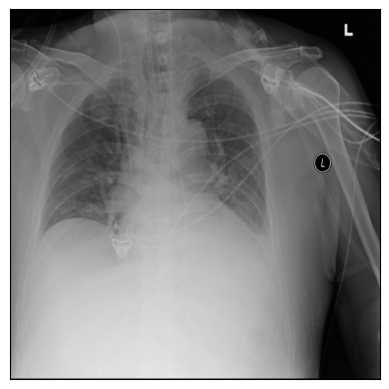

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


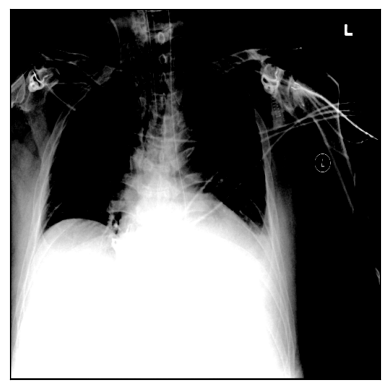

In [5]:
imageId = 7

images, labels, concepts, extra = next(iter(test_loader))
orig_imgs = extra["orig_img"]
image, label = images[imageId].to(device), labels[imageId].to(device)

# print / show input
print("True image size (channels, width, height):", image.size())
print("True  image concepts:", concepts[imageId])

print(orig_imgs[imageId].size())

plt.xticks([])
plt.yticks([])
plt.imshow(orig_imgs[imageId].squeeze().permute(1, 2, 0))
plt.show()

plt.xticks([])
plt.yticks([])
plt.imshow(images[imageId].squeeze().permute(1, 2, 0))
plt.show()

In [6]:
"""
image, concepts = transform(orig_image).to(device), torch.FloatTensor(samples[0][1]).to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None

# get model prediction and LRP map for classification
prediction = XtoC(image)

print(prediction)

pred_concepts_readable = torch.nn.Sigmoid()(prediction)
print("Predicted concepts:", pred_concepts_readable)

# print concept as string if prediction is >= 0.5
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        print(f"id: {idx},", f"concept name: {concept_index_to_string(idx)},", f"sig value: {i.item()}")
"""


image, label = images[imageId].to(device), labels[imageId].to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None

# get model prediction
prediction = XtoC(image)

pred_concepts_readable = torch.nn.Sigmoid()(prediction)
print("Predicted concepts:", pred_concepts_readable)

# print concept as string if prediction is >= 0.5
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        print(f"id: {idx},", f"concept name: {concept_index_to_string(idx)},", f"sig value: {i.item()}")

Predicted concepts: tensor([[0.2537, 0.6810, 0.6262, 0.6919, 0.8315]], grad_fn=<SigmoidBackward0>)
id: 1, concept name: edema, sig value: 0.6809666752815247
id: 2, concept name: consolidation, sig value: 0.6262285113334656
id: 3, concept name: atelectasis, sig value: 0.691940188407898
id: 4, concept name: pleural_effusion, sig value: 0.831527054309845


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from captum.attr import IntegratedGradients, Saliency, GuidedGradCam
from captum.attr import NoiseTunnel
from captum.attr import visualization as viz


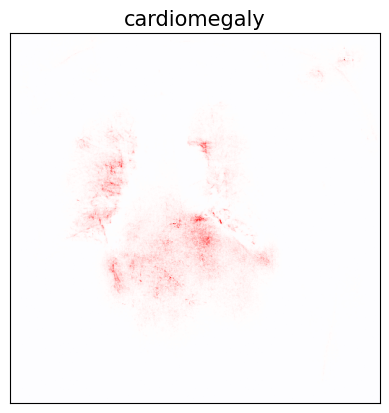

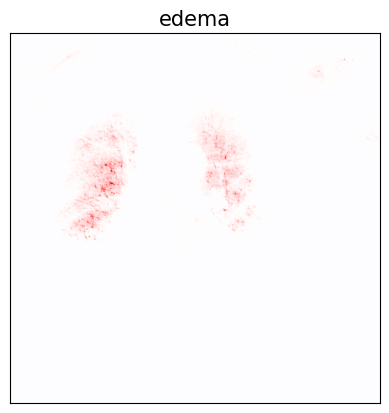

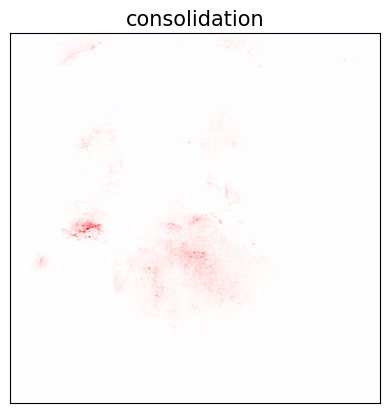

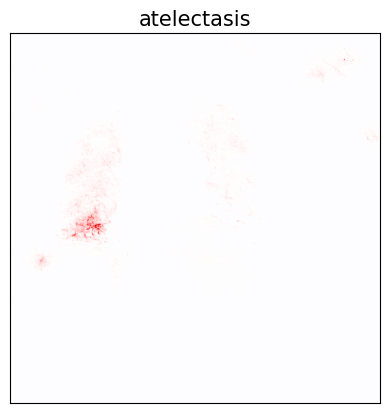

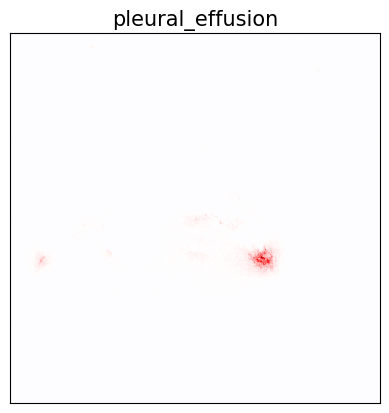

In [8]:
# A single figure is defined as putting this in a loop quickly uses up all system memory.
# This figure is reused for all plots
FIG, AX = plt.subplots()

ig = IntegratedGradients(XtoC)
nt = NoiseTunnel(ig)

image, label = images[imageId].to(device), labels[imageId].to(device)
image = image.unsqueeze(0).to(device)
image.requires_grad_(True)
image.grad = None  # Reset gradient

baselines = image * 0

outputs = XtoC(image)

for index in range(outputs.size(1)):
	# get saliecy maps for each concept
	filter_out = torch.zeros_like(outputs)
	filter_out[:,index] += 1

	attributions_ig = nt.attribute(
		image,
		target=int(index),
		baselines=baselines,
		nt_type='smoothgrad_sq',
		nt_samples=25,
		internal_batch_size=25,
		stdevs=0.2
	)

	attr = heatmap(attributions_ig, cmap_name='seismic')

	plt.xticks([])
	plt.yticks([])
	plt.title(label=concept_index_to_string(index), fontsize=15)
	plt.imshow(attr.squeeze(), cmap='seismic')
	#plt.savefig(f'temp/{i}.png')
	plt.show()

	plt.close()

/home/jack/Documents/papers/code/captum/captum/attr/_core/guided_backprop_deconvnet.py:64: UserWarning: Setting backward hooks on ReLU activations.The hooks will be removed after the attribution is finished
  warnings.warn(


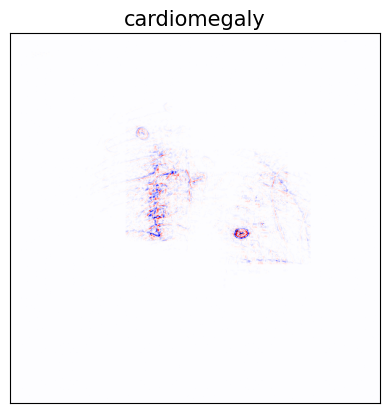

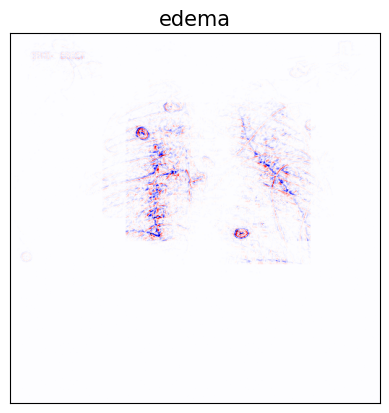

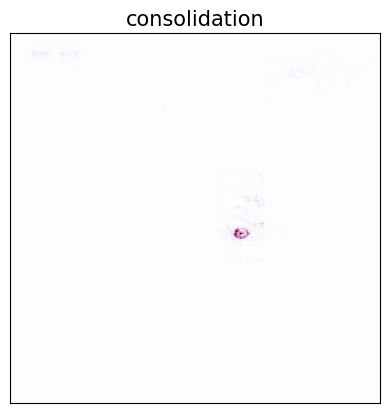

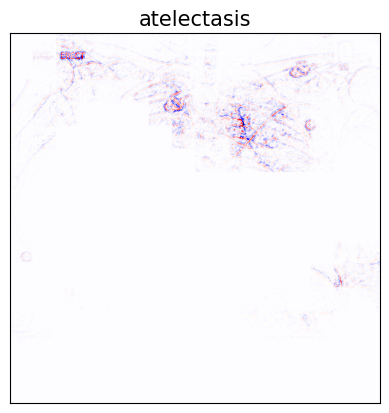

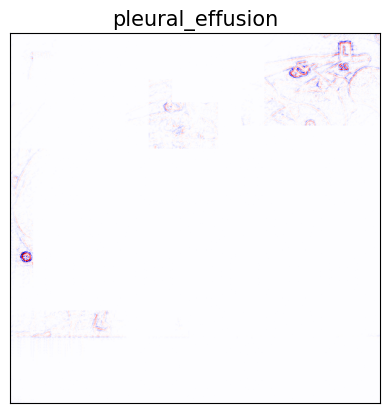

In [19]:
#print(XtoC.backbone.features.denseblock4.denselayer16[5])

# A single figure is defined as putting this in a loop quickly uses up all system memory.
# This figure is reused for all plots
FIG, AX = plt.subplots()

guided_gc = GuidedGradCam(XtoC, XtoC.backbone.features.denseblock4.denselayer16[5])

image, label = images[imageId].to(device), labels[imageId].to(device)
image = image.unsqueeze(0).to(device)
image.requires_grad_(True)
image.grad = None  # Reset gradient

outputs = XtoC(image)

for index in range(outputs.size(1)):
	# get saliecy maps for each concept
	filter_out = torch.zeros_like(outputs)
	filter_out[:,index] += 1

	attribution = guided_gc.attribute(
		image,
		target=int(index),
	)

	attr = heatmap(attribution, cmap_name='seismic')

	plt.xticks([])
	plt.yticks([])
	plt.title(label=concept_index_to_string(index), fontsize=15)
	plt.imshow(attr.squeeze(), cmap='seismic')
	#plt.savefig(f'temp/{i}.png')
	plt.show()

	plt.close()

In [ ]:
XtoC_model_1 = []
XtoC_model_2 = []
XtoC_model_3 = []

for idx, m in enumerate(XtoC.children()):
    if idx < 24:
        XtoC_model_1.append(m)
    elif idx < 46:
        XtoC_model_2.append(m)
    else:
        XtoC_model_3.append(m)

XtoC_model_1 = lrp.Sequential(*XtoC_model_1)
XtoC_model_2 = lrp.Sequential(*XtoC_model_2)
XtoC_model_3 = lrp.Sequential(*XtoC_model_3)

XtoC_model_1.to(device).eval()
XtoC_model_2.to(device).eval()
XtoC_model_3.to(device).eval()

print(XtoC_model_1)
print(XtoC_model_2)
print(XtoC_model_3)

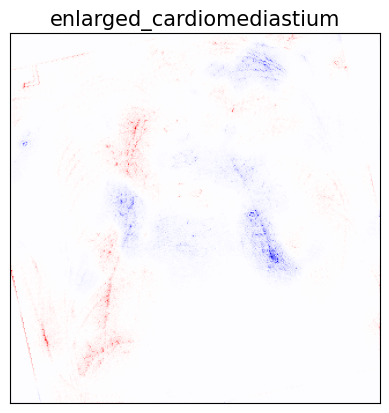

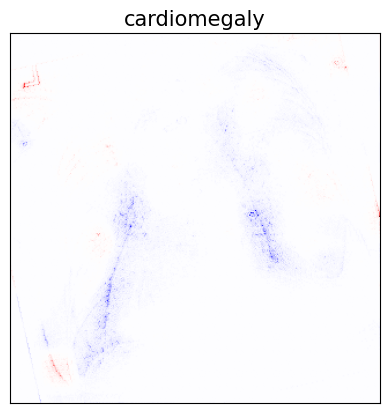

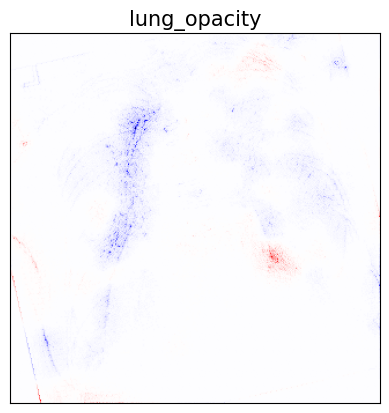

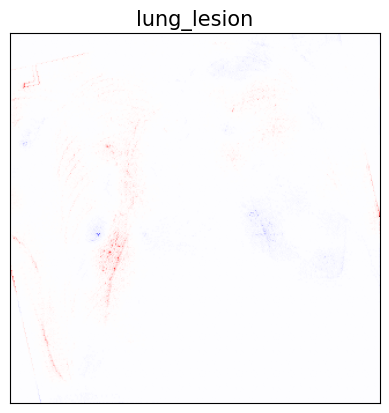

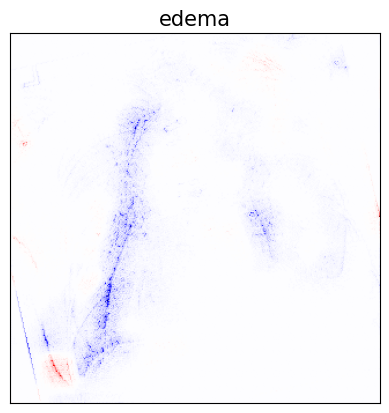

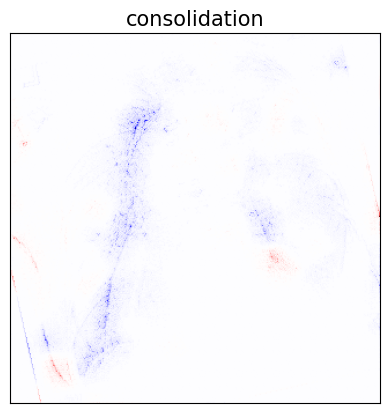

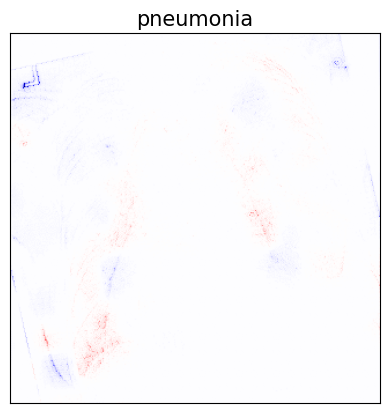

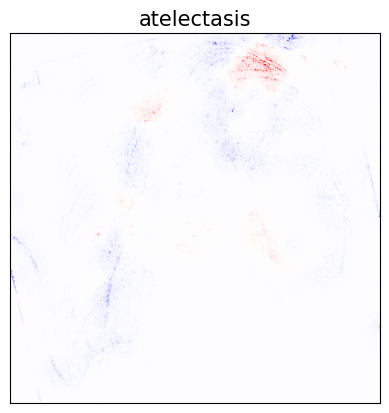

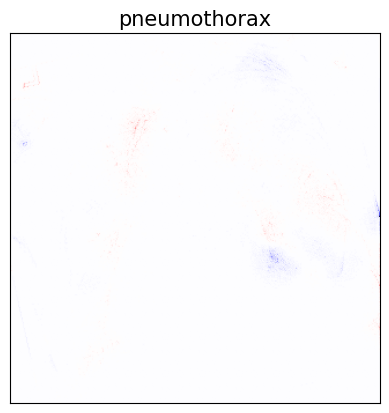

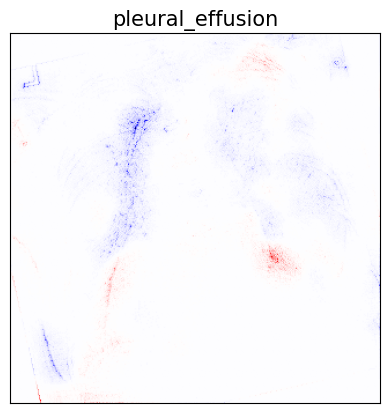

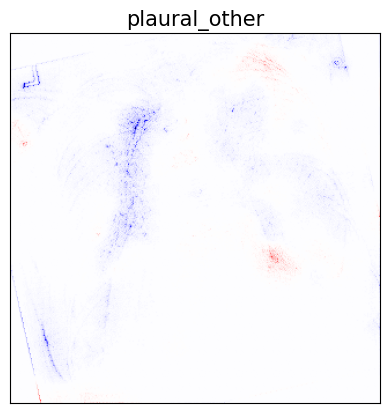

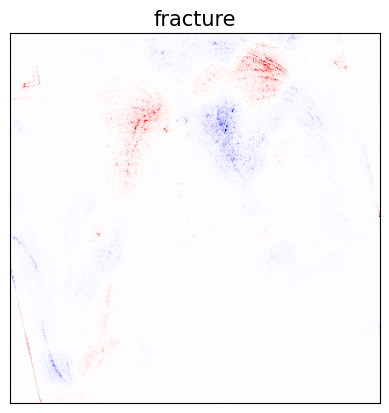

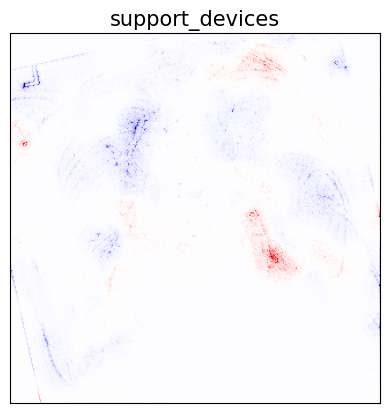

In [21]:
image, concepts = transform(orig_image).to(device), torch.FloatTensor(samples[0][1]).to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None  # Reset gradient

output_1 = XtoC_model_1.forward(image, explain=True, rule="alpha1beta0")
output_2 = XtoC_model_2.forward(output_1, explain=True, rule="epsilon")
pred_concepts = XtoC_model_3.forward(output_2, explain=True, rule="gradient")
    
# get saliecy maps for top 5 concepts
pred_precent_concepts = []
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        pred_precent_concepts.append((idx, i.item()))

pred_precent_concepts = sorted(pred_precent_concepts, key=lambda x: -x[1])

for i in range(pred_concepts.size(1)):
    filter_out = torch.zeros_like(pred_concepts)
    filter_out[:,i] += 1

    # Get the gradient of each input
    image_gradient = torch.autograd.grad(
        pred_concepts,
        image,
        grad_outputs=filter_out,
        retain_graph=True)[0]


    attr = heatmap(image_gradient, cmap_name='seismic')

    plt.xticks([])
    plt.yticks([])
    plt.title(label=concept_index_to_string(i), fontsize=15)
    plt.imshow(attr.squeeze(), cmap='seismic')
    #plt.savefig(f'temp/{i}.png')
    plt.show()

    plt.close() 


# OIS and NIS

In [66]:
import concepts_xai.evaluation.metrics.oracle as oracle
import concepts_xai.evaluation.metrics.niching as niche

def ImputityScore(x_to_c_model, data_loader, mode):
	x_to_c_model.eval()

	c_soft = []
	c_true = []
	with torch.set_grad_enabled(False):
		for images, labels, ground_concepts, extra in tqdm(data_loader, unit="batch"):


			concept_representations = x_to_c_model(images)

			sigmoid_outputs = torch.nn.Sigmoid()(concept_representations.view(concept_representations.size(0), -1))

			c_soft.append(sigmoid_outputs)
			c_true.append(ground_concepts)

	if mode == "oracle":
		score, pred_matrix, oracle_matrix = oracle.oracle_impurity_score(
			c_soft=np.stack(np.concatenate(c_soft, axis=0)),
			c_true=np.stack(np.concatenate(c_true, axis=0)),
			output_matrices=True
		)
		return score, pred_matrix, oracle_matrix
	elif mode == "niche":
		score = niche.niche_impurity_score(
			c_soft=np.stack(np.concatenate(c_soft, axis=0)),
			c_true=np.stack(np.concatenate(c_true, axis=0))
		)
		return score, None, None
	else:
		raise Exception(f"Mode has to have the value 'oracle' or 'niche'")

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 7/7 [00:48<00:00,  6.98s/batch]


2/2 [==============================] - 0s 2ms/step
score: 0.8256257057189942


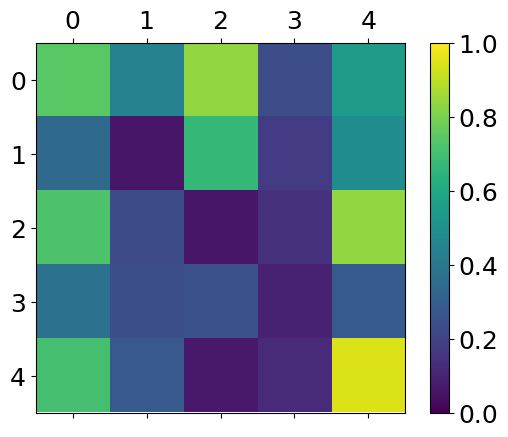

[[0.74545455 0.44444445 0.83809525 0.23529412 0.55151516]
 [0.34545454 0.06111111 0.6666667  0.17892157 0.4848485 ]
 [0.72121215 0.22777778 0.06190476 0.14215687 0.8393939 ]
 [0.37575758 0.23888889 0.25238097 0.09313726 0.28484848]
 [0.7060606  0.2777778  0.06666667 0.12254902 0.94848484]]


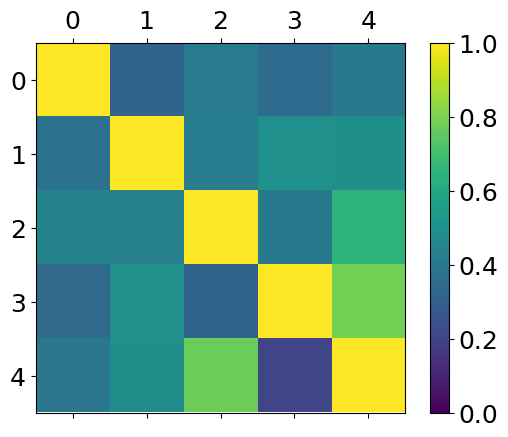

[[1.         0.32386363 0.40714285 0.34871796 0.40128204]
 [0.37698412 1.         0.41904762 0.50384617 0.49615383]
 [0.4484127  0.43560606 1.         0.4051282  0.6474359 ]
 [0.34391534 0.5056818  0.32380953 1.         0.7897436 ]
 [0.39814815 0.4943182  0.77380955 0.21025641 1.        ]]


In [73]:
score, pred_matrix, oracle_matrix = ImputityScore(XtoC, test_loader, mode="oracle")

print("score:", score)

if type(pred_matrix) == np.ndarray:
	for matrix_name in ["pred_matrix", "oracle_matrix"]:
		if matrix_name == "pred_matrix":
			matrix = pred_matrix
		else:
			matrix = oracle_matrix
		fig = plt.figure()
		ax = fig.add_subplot(111)
		cax = ax.matshow(matrix, interpolation='nearest', vmin=0.0, vmax=1.0)
		fig.colorbar(cax)
		plt.show()
		print(matrix)

In [75]:
def normalize_impurity(impurity, n_concepts):
    return impurity / (n_concepts / 2)

norm_fn = lambda x: np.linalg.norm(x, ord='fro')

impurity = normalize_impurity(
	impurity=norm_fn(np.abs(pred_matrix)),
	n_concepts=5
)

print(impurity)

print(pred_matrix.mean())
print(oracle_matrix.mean())

print((pred_matrix * np.eye(5)))
print((pred_matrix * (np.ones((5, 5)) - np.eye(5))))

print((pred_matrix * np.eye(5)).diagonal().mean())

keep_index = np.where(~np.eye(pred_matrix.shape[0],dtype=bool))
print(np.array([pred_matrix[keep_index[0][i], keep_index[1][i]] for i in range(len(keep_index[0]))]).mean())

0.9630759239196778
0.3964321
0.5621322
[[0.74545455 0.         0.         0.         0.        ]
 [0.         0.06111111 0.         0.         0.        ]
 [0.         0.         0.06190476 0.         0.        ]
 [0.         0.         0.         0.09313726 0.        ]
 [0.         0.         0.         0.         0.94848484]]
[[0.         0.44444445 0.83809525 0.23529412 0.55151516]
 [0.34545454 0.         0.66666669 0.17892157 0.4848485 ]
 [0.72121215 0.22777778 0.         0.14215687 0.83939391]
 [0.37575758 0.23888889 0.25238097 0.         0.28484848]
 [0.70606059 0.27777779 0.06666667 0.12254902 0.        ]]
0.3820185035467148
0.40003553


In [54]:
np.ones((5, 5))

array([[1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.]])